# L3 综合实验｜数据获取、存储与报告

本实验整合第 43–46 课：离线数据适配器 → schema 校验 → SQLite 幂等写入 → 指标与图表 → 可追溯清单。

- 环境：`pkm-quant`
- 数据：固定模拟日线，适配器名称仅模拟 yfinance/AkShare 返回结构
- 输出：`outputs/L3_market_store.sqlite`、`L3_data_report.csv/png/json`
- 状态：可运行学习稿

## 1. 研究任务与验收

统一两个“供应商”的列名和复权口径，将结果写入唯一键数据库；重复运行不增加行数；报告同时说明成功资产、失败资产、日期范围、区间收益、最大回撤和输入哈希。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


In [2]:
# 导入本地存储和哈希工具。
import sqlite3
import hashlib

## 2. 两个适配器输出相同的数据契约

研究层只接收 `date/symbol/adjustment/close/volume/source`。接口自身的中文列、MultiIndex 或默认参数不进入后续逻辑。

In [3]:
# 从同一离线快照模拟两个不同供应商，再标准化为统一长表。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])

def adapt_global(symbol):
    raw = daily.loc[daily["symbol"].eq(symbol), ["date", "adj_close", "volume"]].copy()
    if raw.empty:
        raise LookupError(f"{symbol}: empty")
    return raw.rename(columns={"adj_close": "close"}).assign(
        symbol=symbol, adjustment="total-return-like", source="global-offline"
    )[["date", "symbol", "adjustment", "close", "volume", "source"]]

def adapt_a_share(symbol):
    raw = daily.loc[daily["symbol"].eq(symbol), ["date", "close", "volume"]].copy()
    if raw.empty:
        raise LookupError(f"{symbol}: empty")
    return raw.assign(
        symbol=symbol, adjustment="qfq-demo", source="a-share-offline"
    )[["date", "symbol", "adjustment", "close", "volume", "source"]]

frames, status_rows = [], []
for source, symbol, adapter in [
    ("global", "TECH_A", adapt_global),
    ("a_share", "BANK_A", adapt_a_share),
    ("a_share", "MISSING_A", adapt_a_share),
]:
    try:
        result = adapter(symbol)
        frames.append(result)
        status_rows.append({"source": source, "symbol": symbol, "status": "ok", "rows": len(result)})
    except Exception as exc:
        status_rows.append({"source": source, "symbol": symbol, "status": "failed", "rows": 0, "error": str(exc)})

normalized = pd.concat(frames, ignore_index=True)
statuses = pd.DataFrame(status_rows)
display(normalized.head())
display(statuses)
assert normalized.columns.tolist() == ["date", "symbol", "adjustment", "close", "volume", "source"]
assert statuses["status"].tolist() == ["ok", "ok", "failed"]

,date,symbol,adjustment,close,volume,source
0,2023-01-03,TECH_A,total-return-like,36.2134,6241108,global-offline
1,2023-01-04,TECH_A,total-return-like,36.5943,3498641,global-offline
2,2023-01-05,TECH_A,total-return-like,36.0263,2533583,global-offline
3,2023-01-06,TECH_A,total-return-like,35.9828,4052269,global-offline
4,2023-01-09,TECH_A,total-return-like,35.7220,5129985,global-offline


,source,symbol,status,rows,error
0,global,TECH_A,ok,756,NaN
1,a_share,BANK_A,ok,756,NaN
2,a_share,MISSING_A,failed,0,MISSING_A: empty


## 3. SQLite 唯一键与 UPSERT

重复执行同一批次后行数应等于唯一业务键数量，而不是写入次数。

In [4]:
# 建库并把同一批次 UPSERT 两次，验证幂等。
db_path = OUTPUT_DIR / "L3_market_store.sqlite"
if db_path.exists():
    db_path.unlink()
with sqlite3.connect(db_path) as conn:
    conn.execute("""
        CREATE TABLE prices(
          date TEXT, symbol TEXT, adjustment TEXT, close REAL, volume INTEGER, source TEXT,
          PRIMARY KEY(symbol,date,adjustment)
        )
    """)
    sql = """INSERT INTO prices VALUES(?,?,?,?,?,?)
             ON CONFLICT(symbol,date,adjustment) DO UPDATE SET
             close=excluded.close, volume=excluded.volume, source=excluded.source"""
    records = [
        (str(row.date.date()), row.symbol, row.adjustment, row.close, row.volume, row.source)
        for row in normalized.itertuples(index=False)
    ]
    conn.executemany(sql, records)
    conn.executemany(sql, records)
    stored = pd.read_sql_query("SELECT * FROM prices ORDER BY date,symbol", conn, parse_dates=["date"])

print("输入/存储/唯一键:", len(normalized), len(stored), len(normalized.drop_duplicates(["symbol", "date", "adjustment"])))
assert len(stored) == len(normalized)

输入/存储/唯一键: 1512 1512 1512


## 4. 同一结果表驱动指标、图表和清单

,start,end,rows,interval_return,max_drawdown
symbol,,,,,
BANK_A,2023-01-03,2025-11-25,756,0.281476,-0.210284
TECH_A,2023-01-03,2025-11-25,756,1.222376,-0.185165


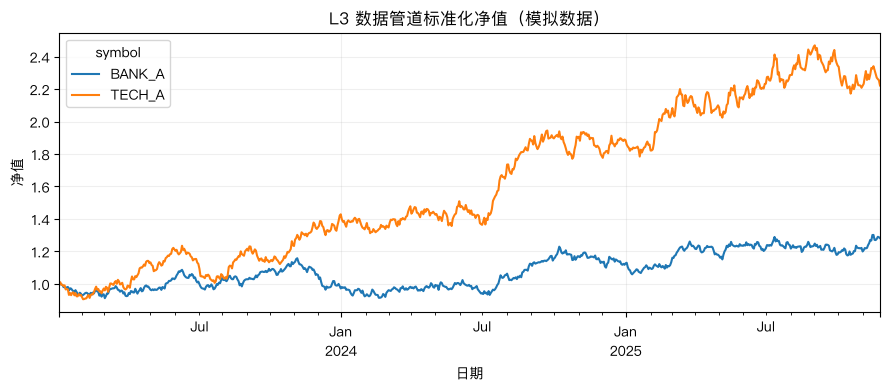

In [5]:
# 按资产计算净值、区间收益和最大回撤。
wide = stored.pivot(index="date", columns="symbol", values="close").sort_index()
nav = wide / wide.iloc[0]
drawdown = nav / nav.cummax() - 1
report = pd.DataFrame({
    "start": wide.apply(lambda s: s.first_valid_index()),
    "end": wide.apply(lambda s: s.last_valid_index()),
    "rows": wide.notna().sum(),
    "interval_return": nav.iloc[-1] - 1,
    "max_drawdown": drawdown.min(),
})
report_path = OUTPUT_DIR / "L3_data_report.csv"
report.to_csv(report_path)
display(report)

axis = nav.plot(figsize=(9, 4), title="L3 数据管道标准化净值（模拟数据）")
axis.set(xlabel="日期", ylabel="净值")
axis.grid(alpha=0.2)
axis.figure.tight_layout()
chart_path = OUTPUT_DIR / "L3_data_report.png"
axis.figure.savefig(chart_path, dpi=150)
plt.show()

In [6]:
# 保存输入哈希、配置、逐资产状态和产物路径。
input_path = DATA_DIR / "daily_prices.csv"
manifest = {
    "lab": "L3",
    "input_sha256": hashlib.sha256(input_path.read_bytes()).hexdigest(),
    "database": db_path.name,
    "report": report_path.name,
    "chart": chart_path.name,
    "statuses": statuses.fillna("").to_dict(orient="records"),
}
manifest_path = OUTPUT_DIR / "L3_data_report.json"
manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
assert all(path.exists() for path in [db_path, report_path, chart_path, manifest_path])
print("L3 验收通过")

L3 验收通过


## 方法边界与复用结论


- 本实验的两个适配器都读取模拟快照，不代表真实 Yahoo/AkShare 结果。
- 真实系统要增加限流、重试、断点水位、数据授权和一手来源复核。
- 区间收益与回撤只用于验证流水线，不能评价虚构资产。


本课代码验证的是方法和数据契约，不是未来收益。迁移到真实研究前，还需重新核对来源授权、复权、时区、可得时间、交易成本和样本外边界。